# Libraries and Data Import

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mohammadtalib786/retail-sales-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'retail-sales-dataset' dataset.
Path to dataset files: /kaggle/input/retail-sales-dataset


In [3]:
df = pd.read_csv(os.path.join(path, 'retail_sales_dataset.csv'))

In [4]:
df.shape

(1000, 9)

# Preprocessing

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [6]:
df.head()

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
df['date'] = pd.to_datetime(df['date'])

In [8]:
df['customer_id'].value_counts().max()

1

There are no repeat purchases, which means, that each customer has only one transaction. To make our RFM customer segmentation meaningful, let's introduce multiple purchases for each customer.

In [9]:
np.random.seed(42)

df['customer_id_new'] = np.random.randint(0, 600, size=1000)
df.head()

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount,customer_id_new
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,102
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,435
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,270
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,106
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,71


In [10]:
df['customer_id_new'].value_counts()

,count
customer_id_new,
98,8
345,7
252,6
232,6
510,6
...,...
355,1
221,1
466,1


In [11]:
df['customer_id_new'] = df['customer_id_new'].apply(lambda x: f'CUST{str(x).zfill(3)}')

In [12]:
df['customer_id'] = df['customer_id_new']
df.head()

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount,customer_id_new
0,1,2023-11-24,CUST102,Male,34,Beauty,3,50,150,CUST102
1,2,2023-02-27,CUST435,Female,26,Clothing,2,500,1000,CUST435
2,3,2023-01-13,CUST270,Male,50,Electronics,1,30,30,CUST270
3,4,2023-05-21,CUST106,Male,37,Clothing,1,500,500,CUST106
4,5,2023-05-06,CUST071,Male,30,Beauty,2,50,100,CUST071


In [13]:
df = df.drop(columns=['customer_id_new'])

# RFM Customer Segmentation

RFM Analysis is a data-driven customer segmentation technique that groups your audience based on their transaction history using three key metrics:
* Recency (R) — How recently did the customer make their last purchase? (Lower days mean higher engagement).
* Frequency (F) — How often does the customer buy within a specific timeframe?
* Monetary (M) — How much total money has the customer spent during this period?


Business Benefits:

* Personalization: Tailor marketing messages instead of sending generic mass emails.
* Budget Optimization: Focus your advertising budget on the segments that bring the highest return on investment (ROI).
* Churn Prevention: Spot at-risk customers early enough to win them back before they leave permanently.


In [14]:
max_date = df['date'].max()
max_date

Timestamp('2024-01-01 00:00:00')

In [15]:
# creating customer-level dataframe
cust_data = df.groupby('customer_id').agg(
    recency = ('date', lambda x: (max_date - x.max()).days),
    frequency = ('transaction_id', 'count'),
    monetary = ('total_amount', 'sum')
)

In [16]:
cust_data.head()

,recency,frequency,monetary
customer_id,,,
CUST000,39,4,1240
CUST001,38,3,2550
CUST002,26,1,50
CUST003,162,1,2000
CUST004,20,5,5240


In [17]:
quantiles = cust_data.quantile(q=[0.25,0.5,0.75])
quantiles

,recency,frequency,monetary
0.25,48.00,1.0,146.25
0.50,115.50,2.0,625.00
0.75,205.25,3.0,1500.00


In [18]:
quantiles = quantiles.to_dict()

In [19]:
RFM_segment = cust_data.copy()

# Arguments (x = value, p = recency, monetary_value, frequency, k = quartiles dict)
def R_Class(x,p,d):
    if x <= d[p][0.25]:
        return 4
    elif x <= d[p][0.50]:
        return 3
    elif x <= d[p][0.75]:
        return 2
    else:
        return 1

# Arguments (x = value, p = recency, monetary_value, frequency, k = quartiles dict)
def FM_Class(x,p,d):
    if x <= d[p][0.25]:
        return 1
    elif x <= d[p][0.50]:
        return 2
    elif x <= d[p][0.75]:
        return 3
    else:
        return 4

RFM_segment['R_Quartile'] = RFM_segment['recency'].apply(R_Class, args=('recency',quantiles,))
RFM_segment['F_Quartile'] = RFM_segment['frequency'].apply(FM_Class, args=('frequency',quantiles,))
RFM_segment['M_Quartile'] = RFM_segment['monetary'].apply(FM_Class, args=('monetary',quantiles,))
RFM_segment['RFMClass'] = RFM_segment.R_Quartile.map(str) \
                            + RFM_segment.F_Quartile.map(str) \
                            + RFM_segment.M_Quartile.map(str)

In [20]:
print("Best Customers: ",len(RFM_segment[RFM_segment['RFMClass']=='444']))
print('Loyal Customers: ',len(RFM_segment[RFM_segment['F_Quartile']==4]))
print("Big Spenders: ",len(RFM_segment[RFM_segment['M_Quartile']==4]))
print('Almost Lost: ', len(RFM_segment[RFM_segment['RFMClass']=='244']))
print('Lost Customers: ',len(RFM_segment[RFM_segment['RFMClass']=='144']))
print('Lost Cheap Customers: ',len(RFM_segment[RFM_segment['RFMClass']=='111']))

Best Customers:  24
Loyal Customers:  65
Big Spenders:  115
Almost Lost:  3
Lost Customers:  3
Lost Cheap Customers:  46


In [21]:
conditions = [
    RFM_segment['RFMClass'].isin(['444', '443', '344', '343']),
    RFM_segment['RFMClass'].isin(['434', '433', '334', '333']),
    RFM_segment['RFMClass'].isin(['414', '413', '424', '423']),
    RFM_segment['RFMClass'].isin(['411', '412', '421', '422']),
    RFM_segment['RFMClass'].isin(['144', '143', '134', '133']),
    RFM_segment['RFMClass'].isin(['244', '243', '242', '234', '233', '232']),
    RFM_segment['RFMClass'].isin(['431', '432', '331', '332', '321', '322', '311', '312']),
    RFM_segment['RFMClass'] == '111'
]

choices = [
    'Champions',
    'Loyal Customers',
    'Potential Loyalists',
    'New Customers',
    'At Risk',
    'About to Sleep',
    'Promising',
    'Lost'
]

RFM_segment['Segment'] = np.select(conditions, choices, default='Hibernating')

In [22]:
RFM_segment.head()

,recency,frequency,monetary,R_Quartile,F_Quartile,M_Quartile,RFMClass,Segment
customer_id,,,,,,,,
CUST000,39,4,1240,4,4,3,443,Champions
CUST001,38,3,2550,4,3,4,434,Loyal Customers
CUST002,26,1,50,4,1,1,411,New Customers
CUST003,162,1,2000,2,1,4,214,Hibernating
CUST004,20,5,5240,4,4,4,444,Champions


In [23]:
segment_size = RFM_segment['Segment'].value_counts().reset_index()
segment_size.columns = ['Segment','Count']
segment_size

,Segment,Count
0,Hibernating,195
1,Promising,52
2,Champions,49
3,Lost,46
4,New Customers,37
5,Loyal Customers,36
6,Potential Loyalists,29
7,About to Sleep,23
8,At Risk,9


In [ ]:
segment_summary = RFM_segment.groupby('Segment').agg(
    customers = ('recency', 'count'),
    avg_recency = ('recency', 'mean'),
    avg_frequency = ('frequency', 'mean'),
    avg_monetary = ('monetary', 'mean')
).round(1).sort_values('customers', ascending=False)
segment_summary

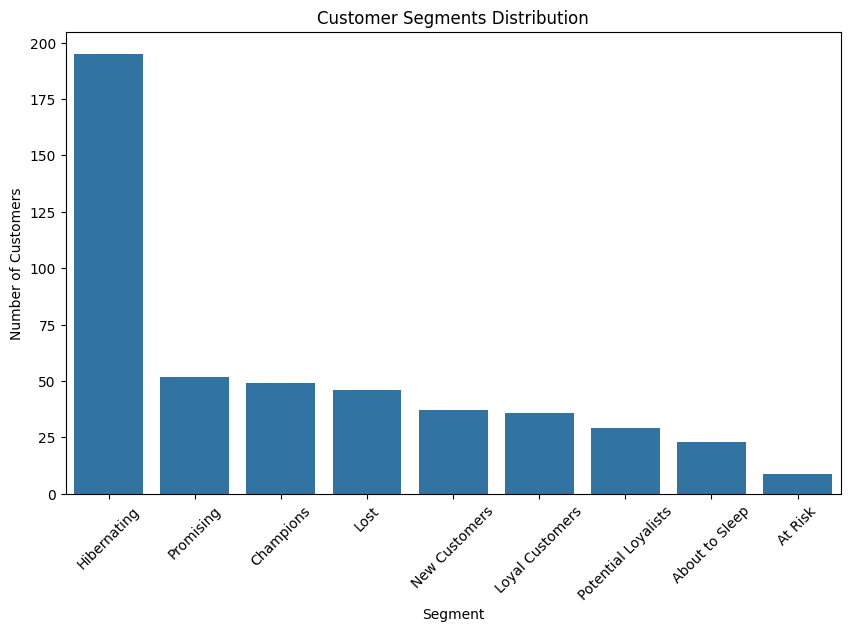

In [24]:
plt.figure(figsize=(10, 6))

sns.countplot(x=RFM_segment['Segment'], order=segment_size['Segment'])

plt.title('Customer Segments Distribution')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

os.makedirs('images', exist_ok=True)
plt.savefig('images/segment_distribution.png', dpi=150, bbox_inches='tight')

plt.show()

# Recommendations


**Champions**(49 customers):

* Retain with VIP status, priority service, and early access to new arrivals without offering direct discounts.

**Loyal Customers**(36 customers):

* Increase average order value using cross-selling, complementary products, and multi-tiered loyalty programs.

**Potential Loyalists**(29 customers):

* Boost purchase frequency through subscriptions, premium category upsells, and time-limited coupons.

**New Customers**(37 customers):

* Onboard via welcome email sequences, helpful tutorials, and short-term promo codes for the second order.

**Promising**(52 customers):

* Grow the average check with product bundles, low-cost accessory recommendations, and free shipping thresholds.

**About to Sleep**(23 customers):

* Prevent churn using personalized selections, customer satisfaction surveys, and expiring bonus reminders.

**At Risk** (9 customers):

* Reactivate former high-value buyers with maximum discounts, direct manager calls, and strong win-back offers.

**Hibernating** (195 customers):

* Activate via low-cost automated email workflows featuring deep discounts on universally popular products.

**Lost** (46 customers):

* Send one final last-chance campaign and archive from the active CRM database to cut marketing expenses.
